*NLP @ HSE DSBA, autumn 2026. Author: Daria Andreeva*

# Seminar 9 — RAG: Retrieval Meets Generation

In this notebook we get to know RAG systems: how they are built, how they are modified, and when you need one at all.

The lecture was about search on its own. Here we bolt it to a generator and measure every piece on one corpus — with one
warning that runs through the whole notebook: the golden set has 20 questions, so one question that changes its answer
moves a metric by 0.05.

# Some dependencies

In [ ]:
# Colab setup. If needed, uncomment the following lines to install dependencies and clone the repository.
#!pip install -q "transformers>=5" sentence-transformers langchain-core langchain-classic langchain-community langchain-text-splitters langchain-huggingface langchain-qdrant qdrant-client rank-bm25 rapidfuzz openpyxl
#!git clone -q --branch autumn-2026 https://github.com/xufana/dsba_nlp.git
#%cd dsba_nlp/week09_rag

In [ ]:
import json
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from tqdm import tqdm

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(device)

# the corpus and the golden set live on the Hugging Face Hub, not in git: fetched once into data/
sys.path.insert(0, "../scripts")
from hub import pull
pull("week09_rag")

## 1. Loading and preparing the data

First, let's settle what data we deal with today.

We work with a dataset built from a Telegram channel, [gonzo_ML](https://t.me/gonzo_ML), which I parsed in advance: 830 posts
from November 2023 to September 2025, in Russian, often with English quotes inside.

In [ ]:
df = pd.read_csv("data/gonzo_dump.csv")
df.head(5)

In [ ]:
df.tail(5)

In [ ]:
df["word_count"] = df["text"].fillna("").str.split().str.len()

plt.hist(df["word_count"].values, bins=30)
plt.title("Words per post");

Let's try to ask a question about our data without the correct contexts we could base the answers on (but we won't).

In [ ]:
longest = df[df["word_count"] > 400].sample(5, random_state=42)["text"].values

for i, text in enumerate(longest):
    print(f"Post number {i + 1}: {text}")
    print("==========================")

Now let's load the so-called "golden set" as well — a number of question–context pairs on which we will count "hits". In my
case the "context" is also the answer; in your case the answer may differ from the context for the sake of naturalness (that
is not so important).

One catch, measured in 2.4: the contexts are retold, not copied — only 5 of the 20 occur in a post word for word. So next to
each question we keep the post it is about, `post_id`: 20 questions about 7 posts. And ten questions the corpus cannot
answer, `no_answer`, for section 3.

In [ ]:
test_df = pd.read_excel("data/golden_mock.xlsx")

# The golden quotes are retold, not copied: only 5 of 20 occur in a post verbatim. So the gold is the post itself —
# the 20 questions are about 7 posts, two or three questions each (checked by reading the posts).
test_df["post_id"] = [3691] * 3 + [2598] * 3 + [2718] * 3 + [2745] * 3 + [2202] * 3 + [3183] * 2 + [3370] * 3

# Questions the corpus cannot answer: six from machine learning that the channel never covered, four from elsewhere.
# Checked by searching the dump for their key terms.
no_answer = [
    "Чем XGBoost отличается от LightGBM при построении деревьев?",
    "Какой результат показала Gemini 3 на бенчмарке ARC-AGI-2?",
    "Как работает GraphSAGE и чем он отличается от GCN?",
    "Как выбрать число кластеров в k-means?",
    "Почему случайный лес меньше переобучается, чем одно решающее дерево?",
    "Как устроен negative sampling в word2vec?",
    "Как сварить борщ?",
    "Как оформить налоговый вычет за лечение зубов?",
    "Во сколько открывается Третьяковская галерея по воскресеньям?",
    "Как взять ипотеку под семейную ставку?",
]

In [ ]:
test_df.head(5)

In [ ]:
test_df["question"][1]

In [ ]:
test_df["text"][2]

## 2. Simple RAG

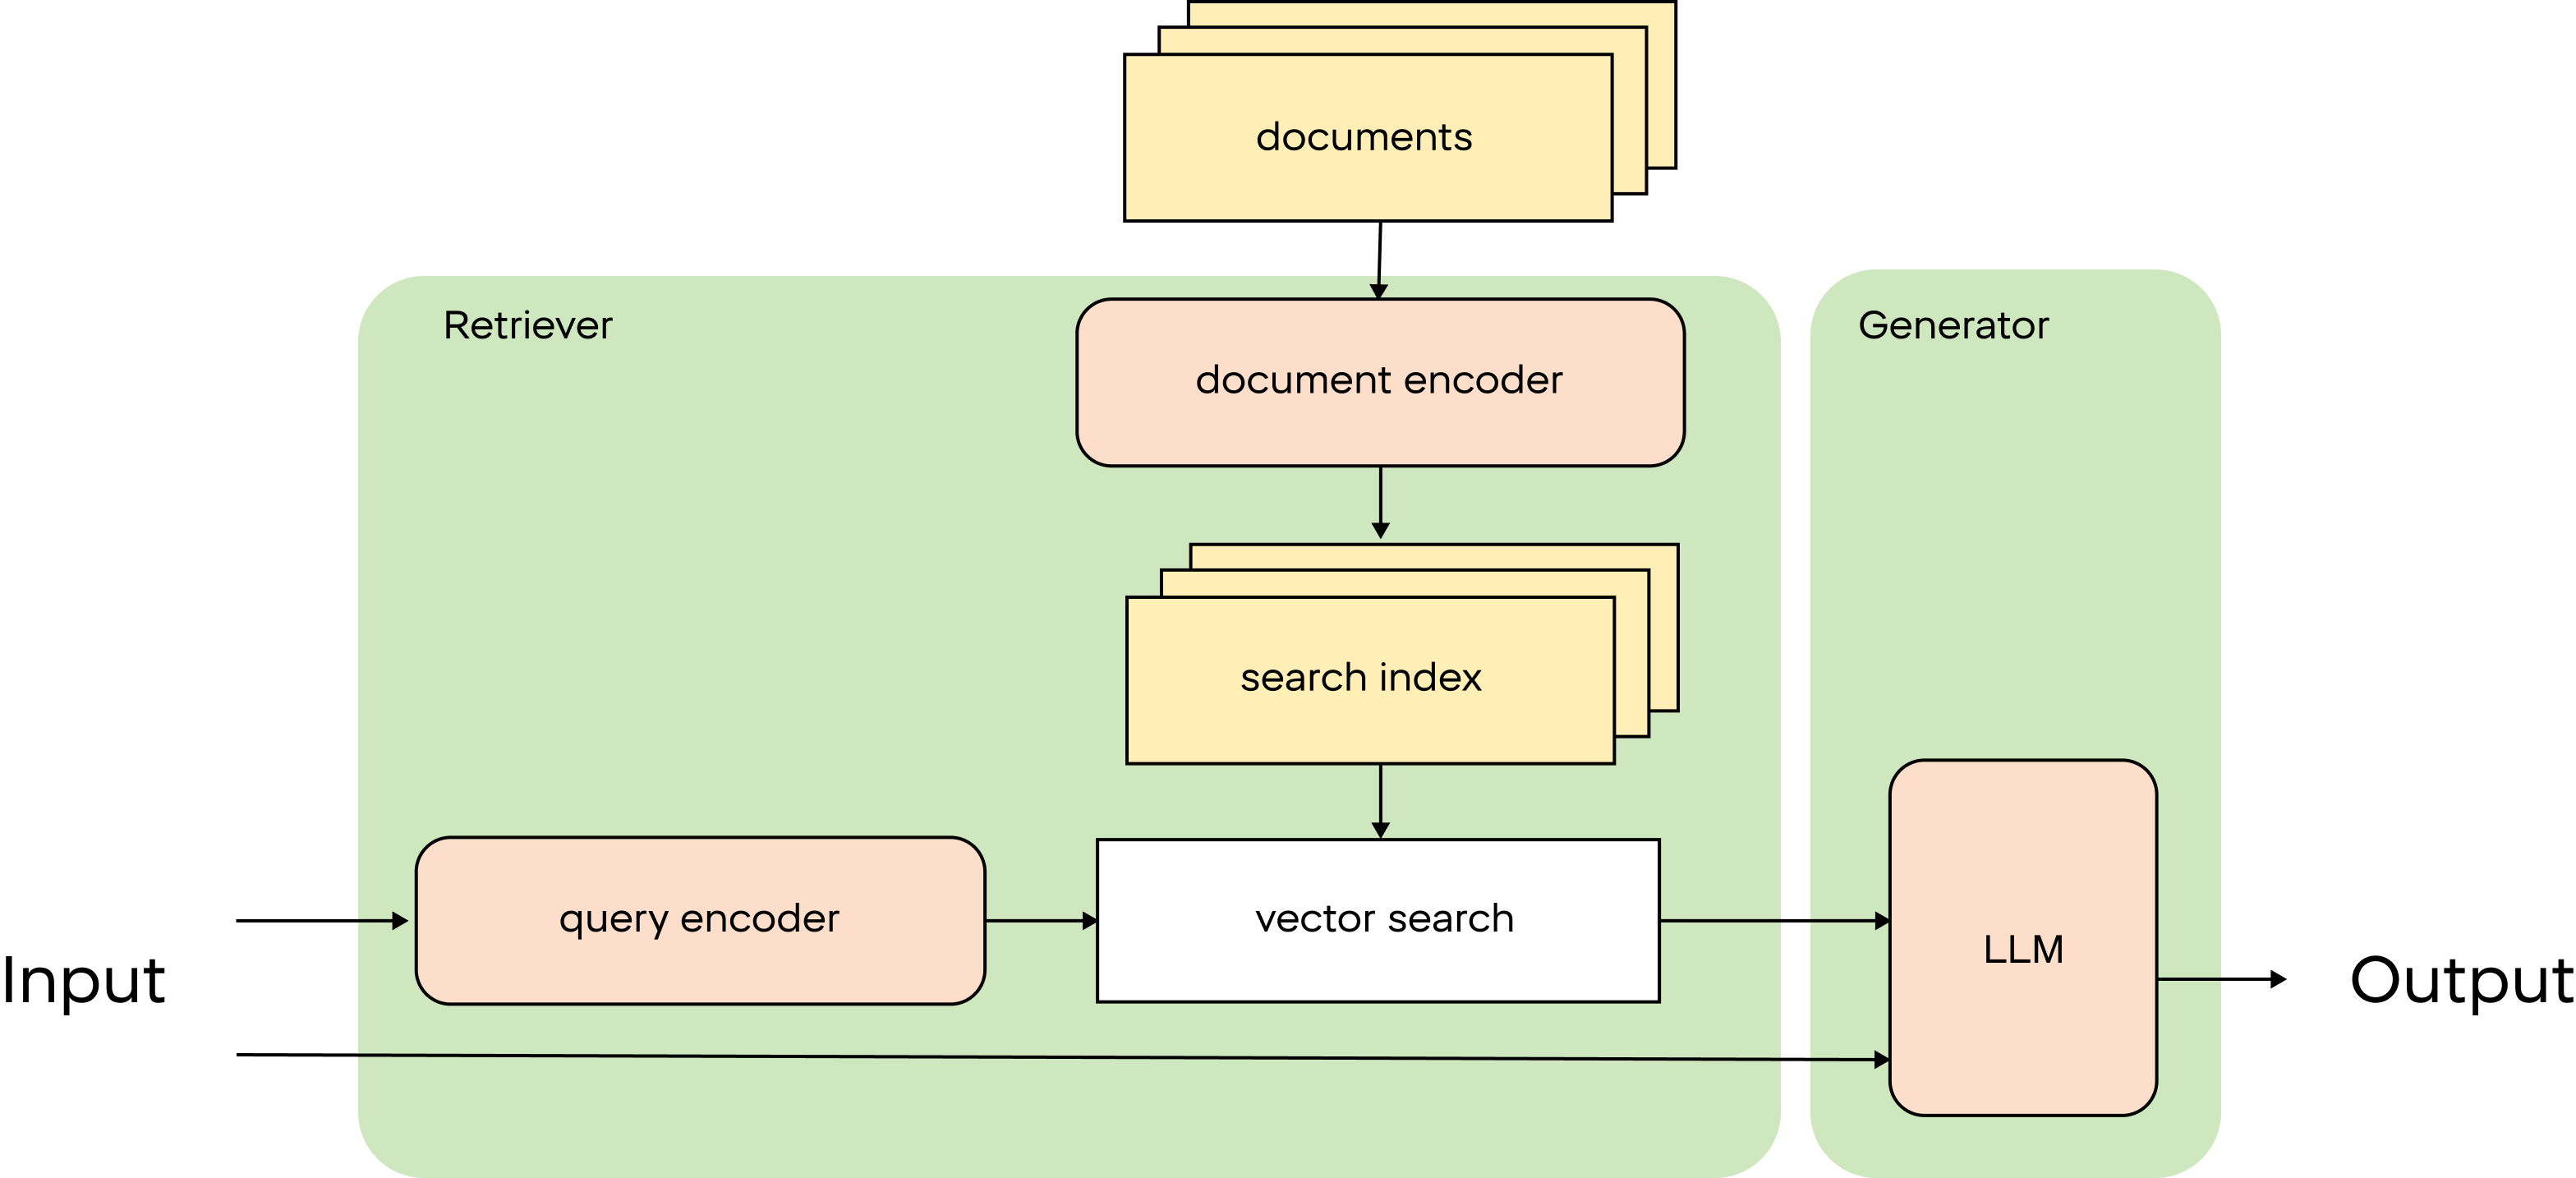

Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks, https://arxiv.org/abs/2005.11401

### 2.1. Defining the data

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_qdrant import QdrantVectorStore
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import PromptTemplate
from langchain_core.documents import Document

In [ ]:
doc_list = RecursiveCharacterTextSplitter().split_documents([
    Document(page_content=row["text"], metadata={"title": row["id"]})
    for _, row in df.iterrows()
])
print(len(df), 'posts ->', len(doc_list), 'documents')  # the default splitter cuts at 4000 characters

**Symmetric search**, as a sketch: index the questions to a text instead of the text itself — a user's question looks like a question, not like a paragraph.

In [ ]:
# symsearch

"""
doc_list = RecursiveCharacterTextSplitter().split_documents([
    Document(
        page_content=row['question'],
        metadata={
            "title": row['id'],
            "text": row['text']
            }
        )
        for i, row in df.iterrows()
    ])

document.metadata['text']
"""

In [ ]:
"""
question_1 -> question_generated(text_1)

question_1 -> text_1
question_1 -> text_2

documents[text_1, text_2]

"""

"""
question_1 -> question_generated(text_1)

question_1 -> text_1
question_2 -> text_1

documents[question_1, question_2]

"""

In [ ]:
df.iloc[0]["text"]

In [ ]:
doc_list[0]

In [ ]:
doc_list[0].page_content

In [ ]:
doc_list[0].metadata

### 2.2. Defining the embeddings

To encode documents and queries we use **`BAAI/bge-m3`** — a symmetric multilingual model that needs no special prefixes
for queries. More: [huggingface.co/BAAI/bge-m3](https://huggingface.co/BAAI/bge-m3).

In [ ]:
# symmetric model
embed_model_name = "BAAI/bge-m3"
embed_model_kwargs = {"device": device}
embed_encode_kwargs = {"normalize_embeddings": True}
query_encode_kwargs = {}

# asymmetric model
"""
embed_model_name = "intfloat/multilingual-e5-large"
embed_model_kwargs = {"device": device}
encode_kwargs = {"prompt": "passage: "}       # prompts
query_encode_kwargs = {"prompt": "query: "}   # prompts
"""

embeddings = HuggingFaceEmbeddings(
    model_name=embed_model_name,
    model_kwargs=embed_model_kwargs,
    encode_kwargs=embed_encode_kwargs,
    query_encode_kwargs=query_encode_kwargs,
)

**⭐ Task:** Try replacing `BAAI/bge-m3` with another model from the [MTEB Russian Leaderboard](https://huggingface.co/spaces/mteb/leaderboard?language=rus). How do Hit@k and NDCG@k in section 2.4 change?

### 2.3. Defining the vector DB

In [ ]:
qdrant = QdrantVectorStore.from_documents(
    doc_list,
    embeddings,
    location=":memory:",
    collection_name="documents",
)

**Bet:** `qdrant.as_retriever()` with no arguments — how many documents does it return for a query?

In [ ]:
question = "Как быть, если в промптах для LLM содержится нерелевантная информация?"
len(qdrant.as_retriever().invoke(question))

Four: LangChain's default `k`, for every retriever (`BM25Retriever` too). We compare retrievers by their top-10, so every one of them gets `k = 10`.

In [ ]:
qdrant_retriever = qdrant.as_retriever(search_kwargs={"k": 10})
qdrant_retriever.invoke(question)[:2]

In [ ]:
results = qdrant.similarity_search_with_score(question, k=2)
results

Now let's split everything into chunks (we take the PD retriever, since it does quite well on long texts).

The children get a collection of their own: added to `qdrant`, they would also turn up in the plain dense search above.

In [ ]:
from langchain_classic.retrievers import ParentDocumentRetriever
from langchain_core.stores import InMemoryStore
from qdrant_client import QdrantClient, models

# This text splitter is used to create the parent documents
parent_splitter = RecursiveCharacterTextSplitter(chunk_size=512)
# This text splitter is used to create the child documents
# It should create documents smaller than the parent
child_splitter = RecursiveCharacterTextSplitter(chunk_size=120, chunk_overlap=0)

client = QdrantClient(":memory:")
client.create_collection("children", vectors_config=models.VectorParams(size=1024, distance=models.Distance.COSINE))
child_store = QdrantVectorStore(client=client, collection_name="children", embedding=embeddings)

store = InMemoryStore()

pd_retriever = ParentDocumentRetriever(
    vectorstore=child_store,
    docstore=store,
    child_splitter=child_splitter,
    # parent_splitter=parent_splitter,
    search_kwargs={"k": 400},   # 120-character children: ten different posts can take a few hundred of them
)

In [ ]:
pd_retriever.add_documents(doc_list)

In [ ]:
# PD by hand
"""
doc_list = RecursiveCharacterTextSplitter().split_documents([
    Document(
        page_content=row['text'],
        metadata={
            "title": row['id']
            }
        )
        for i, row in df.iterrows()
    ], chunk_size=...)
"""

smaller_doc_list = child_splitter.split_documents([
    Document(
        page_content=doc.page_content,
        metadata={
            "title": doc.metadata["title"],
            "bigger_chunk": doc.page_content,
            }
        )
        for doc in doc_list
    ])

In [ ]:
document = smaller_doc_list[0]

In [ ]:
document.page_content  # -- the smaller chunk

In [ ]:
document.metadata["bigger_chunk"]  # -- the bigger chunk

**⭐ Task:** Change `chunk_size` and `chunk_overlap` of `child_splitter` and rerun section 2.4. How do Hit@k and MRR of the PD retriever change? At what chunk size is quality highest?

### 2.4. Checking retrieval

"The retriever found the answer" is never observed directly: it is replaced by a **proxy** that can be checked
automatically, and the choice decides what the metric measures. A hit can be counted
- by **metadata**: the retrieved chunk carries the id of the post (document, section, URL) labelled as the answer —
  needs the golden set written down as ids and the id carried by every chunk;
- by **text**: the golden quote occurs in the retrieved text, exactly or by fuzzy match above a threshold — needs only a
  quote, breaks when the quote was retold;
- by **a model**: an LLM reads the question and the chunk and says whether it answers (see the bonus on LLM-as-a-judge).

The first version of this section used the text proxy: a retrieved text is a hit if
`fuzz.partial_ratio(golden quote, text) >= 80`.

**Bet:** with that rule, what is the best Hit@10 *any* retriever can reach on our 20 questions?


In [ ]:
from rapidfuzz import fuzz

best = [max(fuzz.partial_ratio(quote, d.page_content) for d in doc_list) for quote in test_df["text"]]
print("quotes that reach 80 against at least one document:", sum(b >= 80 for b in best), "of", len(best))

one_word = [t for t in df["text"].fillna("") if 0 < len(t.strip()) <= 12]   # "Найс", "Automation", ...
print(len(one_word), "posts of at most 12 characters; the best any of them scores against a golden quote:",
      max(fuzz.partial_ratio(q, t) for q in test_df["text"] for t in one_word))

The first number is the ceiling the first version of the table hit — the three best retrievers all stopped at exactly
0.65, the share of quotes that can match at all: the others are retold too freely to reach 80 even against their own post.
The second is the other blind spot: `partial_ratio` slides the shorter string along the longer one, so a one-word post is
compared with its best-matching few letters of the quote.

From here on a hit is a document from the gold post — the metadata proxy: every chunk carries its post's id in
`metadata["title"]`, and the golden set says which post answers each question.

In [ ]:
def gold_rank(docs, gold_id):
    """1-based position of the first document from the gold post, None if it is not there."""
    return next((i for i, d in enumerate(docs, start=1) if d.metadata.get("title") == gold_id), None)


def summarize(ranks, k_values=(1, 3, 5, 10)):
    """Hit rate@k (one relevant post per question, so it is recall@k), MRR and NDCG@k from the gold ranks."""
    n = len(ranks)
    return {
        "Hit@k": {k: sum(1 for r in ranks if r and r <= k) / n for k in k_values},
        "MRR": sum(1 / r for r in ranks if r) / n,
        "NDCG@k": {k: sum(1 / np.log2(r + 1) for r in ranks if r and r <= k) / n for k in k_values},
    }


def evaluate_retriever(retriever_fn, test_df, k=10):
    """Run the retriever on every golden question; return the metrics and the rank of the gold post per question."""
    ranks = [gold_rank(retriever_fn(q)[:k], gid) for q, gid in zip(test_df["question"], test_df["post_id"])]
    return {**summarize(ranks), "ranks": ranks}

In [ ]:
results_summary = {}   # the summary table, filled as we go


def print_metrics(metrics, name="Retriever"):
    """Print the metrics and draw them."""
    print(f"\n=== {name} ===")
    k_values = list(metrics["Hit@k"].keys())
    print("Hit@k:  " + "  ".join(f"Hit@{k}={v:.3f}" for k, v in metrics["Hit@k"].items()))
    print(f"MRR:    {metrics['MRR']:.3f}")
    print("NDCG:   " + "  ".join(f"NDCG@{k}={v:.3f}" for k, v in metrics["NDCG@k"].items()))
    print("rank of the gold post per question:", metrics["ranks"])

    fig, axes = plt.subplots(1, 3, figsize=(14, 3))
    axes[0].bar([f"Hit@{k}" for k in k_values], [metrics["Hit@k"][k] for k in k_values], color="skyblue")
    axes[0].set_title(f"Hit@k — {name}");  axes[0].set_ylim(0, 1); axes[0].grid(axis="y", alpha=.5)
    axes[1].bar(["MRR"], [metrics["MRR"]], color="salmon")
    axes[1].set_title(f"MRR — {name}");    axes[1].set_ylim(0, 1); axes[1].grid(axis="y", alpha=.5)
    axes[2].bar([f"NDCG@{k}" for k in k_values], [metrics["NDCG@k"][k] for k in k_values], color="lightgreen")
    axes[2].set_title(f"NDCG@k — {name}"); axes[2].set_ylim(0, 1); axes[2].grid(axis="y", alpha=.5)
    plt.tight_layout(); plt.show()

#### Qdrant (semantic search)

In [ ]:
qdrant_metrics = evaluate_retriever(qdrant_retriever.invoke, test_df)
print_metrics(qdrant_metrics, "Qdrant")
results_summary["Qdrant"] = qdrant_metrics

#### Parent Document Retriever

In [ ]:
pd_metrics = evaluate_retriever(pd_retriever.invoke, test_df)
print_metrics(pd_metrics, "Parent Document Retriever")
results_summary["PD-Retriever"] = pd_metrics

In [ ]:
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever

bm25_retriever = BM25Retriever.from_documents(doc_list)   # tokenises with text.split(): case and punctuation stay
bm25_retriever.k = 10

ensemble_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, qdrant_retriever],
    weights=[0.5, 0.5],  # BM25 + Qdrant
)

#### BM25 (lexical search)

In [ ]:
bm25_metrics = evaluate_retriever(bm25_retriever.invoke, test_df)
print_metrics(bm25_metrics, "BM25")
results_summary["BM25"] = bm25_metrics

**Bet:** `BM25Retriever` splits text with `str.split()`, so for it `LoRA,` and `lora` are two different words. Lower-case everything and drop the punctuation — does MRR move by more than one question's worth (0.05)?

In [ ]:
bm25_lower = BM25Retriever.from_documents(doc_list, preprocess_func=lambda t: re.findall(r"\w+", t.lower()))
bm25_lower.k = 10

bm25_lower_metrics = evaluate_retriever(bm25_lower.invoke, test_df)
print_metrics(bm25_lower_metrics, "BM25, lower case")
results_summary["BM25, lower case"] = bm25_lower_metrics

#### Ensemble (BM25 + Qdrant)

In [ ]:
ensemble_metrics = evaluate_retriever(ensemble_retriever.invoke, test_df)
print_metrics(ensemble_metrics, "Ensemble (BM25 + Qdrant)")
results_summary["Ensemble"] = ensemble_metrics

**⭐⭐ Task:** `evaluate_retriever` assumes exactly one right post per question. Add support for **several relevant documents** per question (NDCG with several non-zero grades). What changes in the results?

## 3. Modifications of RAG

### 3.1. Query Expansion

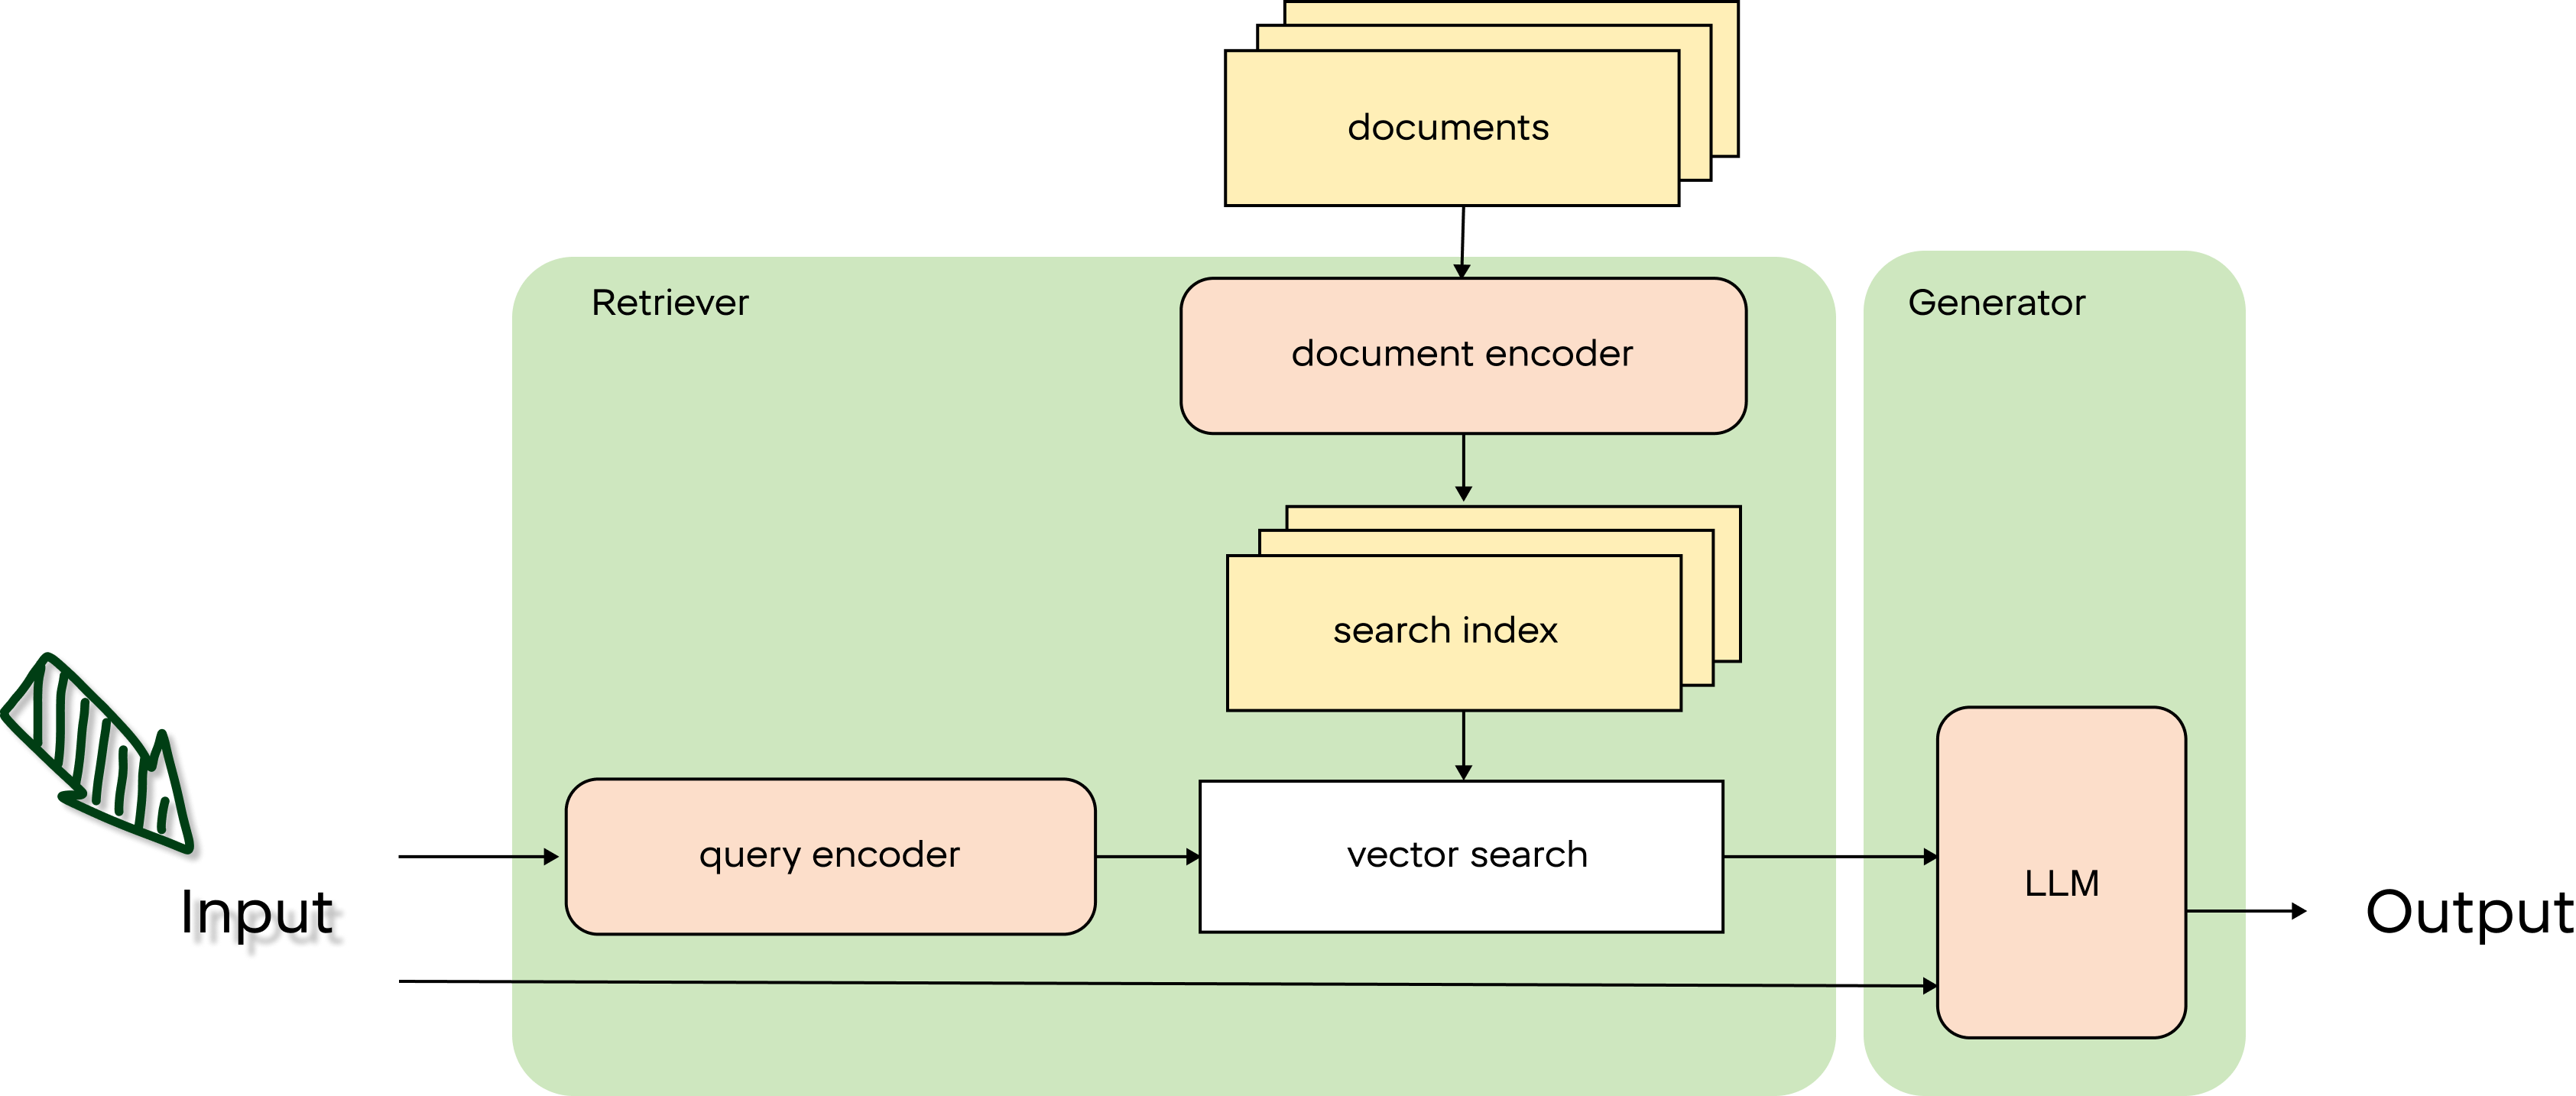

It often happens that users ask questions not at all the way we expect: with typos, incompletely, illiterately — and we need to be able to handle it (because we have no choice).

As a rule, we solve the problem of non-standard but complete queries by rephrasing the user's question:

In [ ]:
from transformers import pipeline

generation_pipeline = pipeline(
    "text-generation",
    model="RefalMachine/ruadapt_qwen2.5_3B_ext_u48_instruct_v4",
    device=device,
    dtype=torch.float16 if device.type == "cuda" else torch.bfloat16 if device.type == "mps" else torch.float32,
)

In [ ]:
# ованц -> аванс

In [ ]:
queries = [
    "чё делать если в промптах нерелевантная инфа?",
    "как устроенны свзи и обучени в архетектуре кан?",   # typos: rephrasing should fix them
    "pathfinder как отбирает кандидатов",                # a name the model may not know
    "гре инструкция по печи?",                           # a cut-off word: «где»
    "когда ованц?",                                      # written as it sounds: «аванс»
]
for original in queries:
    messages = [
        {"role": "system", "content": "Ты LLM-инженер и должен перефразировать вопросы пользователя, исправив грамматику, но не меняя смысл."},
        {"role": "user", "content": original},
    ]
    paraphrased = generation_pipeline(messages, max_new_tokens=256, do_sample=True, temperature=0.5, top_p=0.9)[0]["generated_text"][-1]["content"]
    print(f"{original}\n  → {paraphrased}\n")


Rephrasing is often enough on its own: typos, slang and transliteration get fixed, and the question meets the words of
the documents. But the model rephrases what it *understood*: a name it does not know, a cut-off word or a word written as
it sounds becomes something else — confidently and grammatically. Read the last three rows: nothing in the rephrased text
says it went wrong, so log the rephrasing next to the original, and search with both.


The prompts of section 3 in one place. From here on generation is greedy (`do_sample=False`), so a rerun gives the same answers — on 20 questions one changed answer is 0.05.

In [ ]:
QE_SYSTEM = ("Ты LLM-инженер и должен перефразировать вопросы пользователя, исправив грамматику, но не меняя смысла. "
             "Отвечай только перефразированным вопросом, без пояснений.")
HYDE_SYSTEM = ("Напиши короткий (2-3 предложения) гипотетический ответ на вопрос, как если бы он был фрагментом "
               "документа в базе знаний. Только текст ответа, без пояснений.")
CRAG_SYSTEM = ("Ты классификатор релевантности. Ответь ТОЛЬКО \"yes\" или \"no\": содержит ли контекст информацию, "
               "достаточную для ответа на вопрос?")
RAG_ROLE = "Ты — ассистент, отвечающий на вопросы по контексту ниже."
RAG_IDK = "Если в контексте нет ответа, явно скажи об этом."


def rag_messages(question, context=None, idk=True):
    """The notebook's rag_prompt, with its parts switchable: no context = closed book; idk = the "say so" line."""
    if context is None:
        return [{"role": "user", "content": f"Вопрос: {question}\n\nОтвет:"}]
    head = RAG_ROLE + ("\n" + RAG_IDK if idk else "")
    return [{"role": "user", "content": f"{head}\n\nКонтекст:\n{context}\n\nВопрос: {question}\n\nОтвет:"}]


def judge_messages(question, context, answer, strict=False):
    strictness = " Будь строг: снижай оценку даже за незначительные отклонения." if strict else ""
    prompt = (f"Оцени качество ответа на вопрос.{strictness}\n\n"
              f"Вопрос: {question}\nКонтекст: {context}\nОтвет: {answer}\n\n"
              "Верни JSON строго в таком формате (только JSON, без пояснений):\n"
              '{"relevance": <число 0-5>, "faithfulness": <число 0-5>}')
    return [{"role": "user", "content": prompt}]


def parse_judge(raw):
    m = re.search(r"\{[^}]+\}", raw)
    try:
        s = json.loads(m.group()) if m else {}
        return {"relevance": int(s.get("relevance", -1)), "faithfulness": int(s.get("faithfulness", -1))}
    except (json.JSONDecodeError, ValueError, TypeError):
        return {"relevance": -1, "faithfulness": -1}


def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

#### Checking whether query expansion improved search

In [ ]:
def qe_retriever_fn(question):
    """Rephrase the question with the LLM, then search Qdrant."""
    messages = [{"role": "system", "content": QE_SYSTEM}, {"role": "user", "content": question}]
    expanded = generation_pipeline(messages, max_new_tokens=64, do_sample=False)[0]["generated_text"][-1]["content"].strip()
    return qdrant_retriever.invoke(expanded)


qe_metrics = evaluate_retriever(qe_retriever_fn, test_df)
print_metrics(qe_metrics, "Query Expansion + Qdrant")
results_summary["QE + Qdrant"] = qe_metrics

**⭐ Task:** Implement **Multi-Query**: generate N rephrasings of the question, search with each, merge the results (without duplicates), return the top-10. Compare with single QE by the metrics of `evaluate_retriever`.

### 3.2. HyDE — Hypothetical Document Embeddings

**Idea:** instead of searching by the user's query directly, ask the LLM to generate a *hypothetical answer* — as if it were
already in the knowledge base. The embedding of this hypothetical document is used as the search query.

**Contrast with QE:** QE fixes the *form* of the question (grammar, style), HyDE guesses the *semantics of the answer*. On
short incomplete questions HyDE usually gives a bigger gain.

> Original paper: [Gao et al., 2022 — Precise Zero-Shot Dense Retrieval without Relevance Labels](https://arxiv.org/abs/2212.10496)

**Bet:** our questions are complete, and the encoder was trained on question–passage pairs. Will HyDE beat plain Qdrant here?

In [ ]:
def hyde_retriever_fn(question):
    """HyDE: generate a hypothetical document, search by its embedding."""
    messages = [{"role": "system", "content": HYDE_SYSTEM}, {"role": "user", "content": question}]
    hypothetical_doc = generation_pipeline(messages, max_new_tokens=128, do_sample=False)[0]["generated_text"][-1]["content"].strip()
    return qdrant_retriever.invoke(hypothetical_doc)


hyde_metrics = evaluate_retriever(hyde_retriever_fn, test_df)
print_metrics(hyde_metrics, "HyDE + Qdrant")
results_summary["HyDE + Qdrant"] = hyde_metrics

**⭐⭐ Task:** Compare HyDE and QE on the same golden-set questions. For which kinds of questions does HyDE work better? For which — worse? Try a hybrid strategy: QE first, then HyDE, merge the results.

### 3.3. Reranking

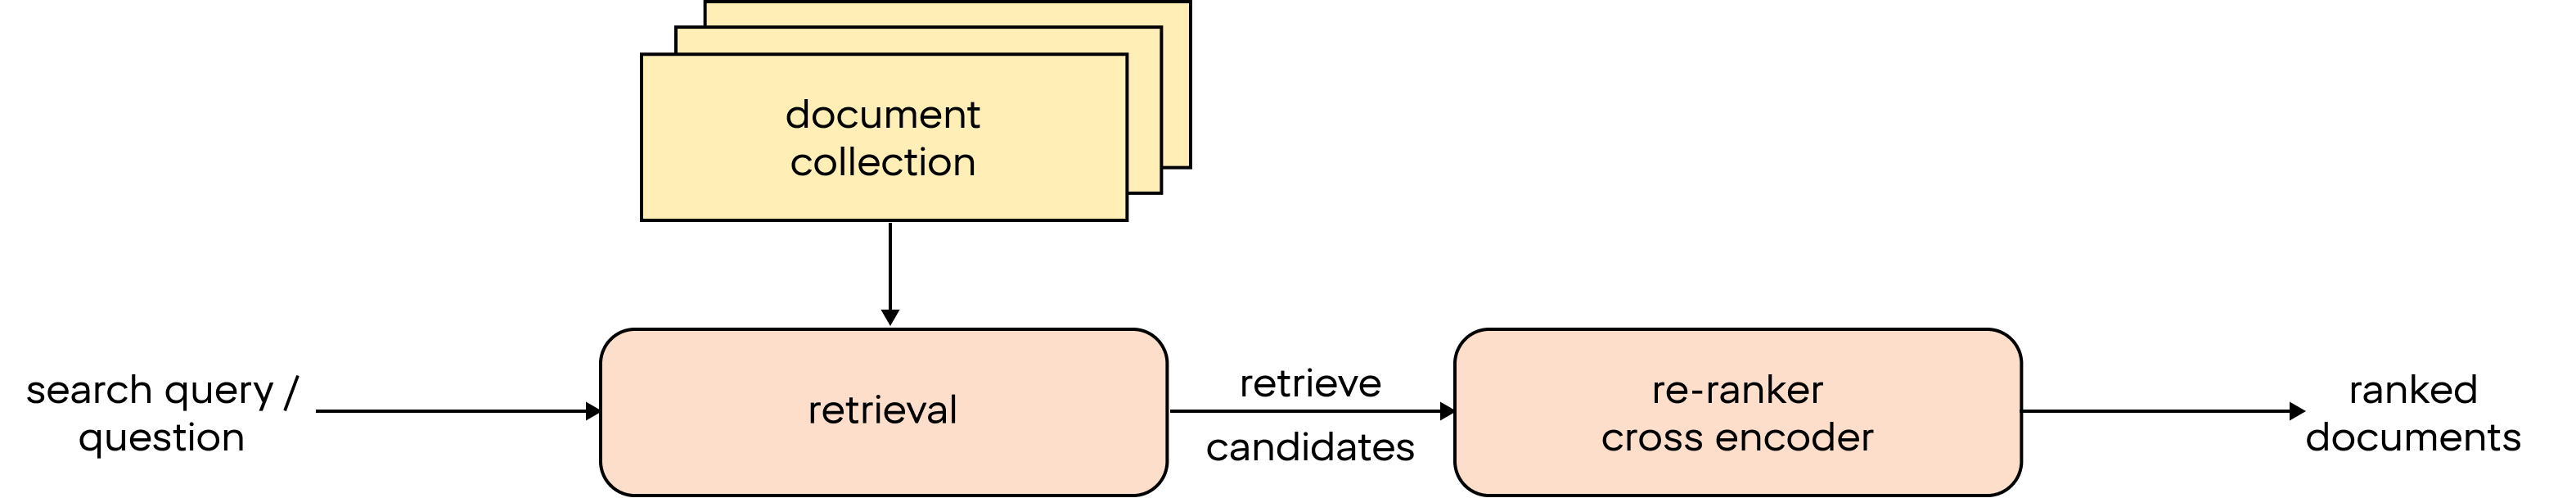

A reranker is a language model that takes two texts and returns how close they are. As the reranker we use a multilingual
model trained for exactly this, `BAAI/bge-reranker-v2-m3`.

Its candidates come from a deeper pool than the ensemble above: BM25 and Qdrant with `k = 50` each, so the number of
candidates is a knob we can turn.

In [ ]:
from langchain_community.cross_encoders import HuggingFaceCrossEncoder

In [ ]:
cross_encoder = HuggingFaceCrossEncoder(
    model_name="BAAI/bge-reranker-v2-m3",
    model_kwargs={"device": device}
)
sum([p.numel() for p in cross_encoder.client.model.parameters()])

In [ ]:
bm25_pool = BM25Retriever.from_documents(doc_list)
bm25_pool.k = 50
pool_retriever = EnsembleRetriever(
    retrievers=[bm25_pool, qdrant.as_retriever(search_kwargs={"k": 50})],
    weights=[0.5, 0.5],
)


def reranking_retriever_fn(question, k_candidates=20):
    """Ensemble -> cross-encoder reranking -> top-10."""
    candidates = pool_retriever.invoke(question)[:k_candidates]
    if not candidates:
        return []
    pairs = [(question, doc.page_content) for doc in candidates]
    scores = cross_encoder.score(pairs)
    ranked = sorted(zip(scores, candidates), key=lambda x: x[0], reverse=True)
    return [doc for _, doc in ranked[:10]]


reranking_metrics = evaluate_retriever(reranking_retriever_fn, test_df)
print_metrics(reranking_metrics, "Ensemble + Reranking")
results_summary["Ensemble + Reranking"] = reranking_metrics

In [ ]:
import gc

gc.collect()

**⭐ Task:** Change `k_candidates` (how many candidates get reranked): try 20, 50, 100. At what value does the system get too slow, and at what value does it lose quality?

### 3.4. CRAG — Corrective RAG

**Idea:** after getting the candidates, the LLM judges their relevance. If the context is irrelevant, the system switches
to a *fallback* strategy (web search, another corpus, or refusing to answer). This lowers the risk of hallucinations when
the retriever returns "similar, but not the right" documents.

> Original paper: [Yan et al., 2024 — CRAG: Corrective Retrieval Augmented Generation](https://arxiv.org/abs/2401.15884)

In the simplified implementation below we use the same `generation_pipeline` for a binary relevance classification.

In [ ]:
def is_relevant_context(question, context):
    """True if the LLM considers the context relevant."""
    messages = [{"role": "system", "content": CRAG_SYSTEM},
                {"role": "user", "content": f"Вопрос: {question}\n\nКонтекст:\n{context}"}]
    response = generation_pipeline(messages, max_new_tokens=10, do_sample=False)[0]["generated_text"][-1]["content"].strip().lower()
    return "yes" in response


def crag_retriever_fn(question):
    """CRAG: qdrant -> relevance check -> fallback (an empty list)."""
    candidates = qdrant_retriever.invoke(question)
    if not candidates:
        return []
    if is_relevant_context(question, candidates[0].page_content):
        return candidates
    else:
        return []  # fallback: "I don't know" for this corpus


crag_metrics = evaluate_retriever(crag_retriever_fn, test_df)
print_metrics(crag_metrics, "CRAG (Qdrant + LLM filter)")
results_summary["CRAG"] = crag_metrics

**Bet:** the same check on the ten questions the corpus cannot answer, where "no" is the right call. How many does it let through?

In [ ]:
said_yes = [is_relevant_context(q, qdrant_retriever.invoke(q)[0].page_content) for q in no_answer]
print(f"the check says 'yes' to {sum(said_yes)} of {len(no_answer)} questions without an answer")

**⭐ Task:** In the current implementation the threshold is binary: "yes" → accept, otherwise → fallback. Change the prompt so that the LLM returns **a score from 1 to 5** (as in G-Eval), and experiment with a numeric threshold. At what threshold does the system fall back too often and lose coverage?

### 3.5. A threshold instead of a judge

The cheapest check has no LLM at all: refuse when the best cosine is below a threshold.

**Bet:** is there a threshold that keeps all 20 golden questions and stops all 10 without an answer?

In [ ]:
top1 = lambda q: qdrant.similarity_search_with_score(q, k=1)[0][1]
golden_top1 = [top1(q) for q in test_df["question"]]
no_answer_top1 = [top1(q) for q in no_answer]

plt.figure(figsize=(8, 1.8))
plt.scatter(golden_top1, np.zeros(len(golden_top1)), label="golden", alpha=.7)
plt.scatter(no_answer_top1, np.ones(len(no_answer_top1)) * .3, label="no answer in the corpus", alpha=.7)
plt.yticks([]); plt.xlabel("best cosine"); plt.legend(loc="upper left"); plt.show()
print(f"lowest golden {min(golden_top1):.3f}, highest without an answer {max(no_answer_top1):.3f}")

### 3.6. What the prompt changes

The same question under three prompts: no context (closed book), the retrieved top-3, and the top-3 plus the line "if the
answer is not in the context, say so". One golden question and one without an answer; the demo page has all 30.

In [ ]:
for q in [test_df["question"][9], no_answer[1]]:
    context = format_docs(qdrant_retriever.invoke(q)[:3])
    print("Q:", q)
    for name, messages in [("closed book", rag_messages(q)),
                           ("context", rag_messages(q, context, idk=False)),
                           ("context + say so", rag_messages(q, context, idk=True))]:
        answer = generation_pipeline(messages, max_new_tokens=128, do_sample=False)[0]["generated_text"][-1]["content"].strip()
        print(f"  [{name}] {answer}\n")

---

## 4. Summary table of retrievers

All the collected metrics in one place.

In [ ]:
rows = []
for name, m in results_summary.items():
    row = {"Retriever": name, "MRR": round(m["MRR"], 3)}
    for k, v in m["Hit@k"].items():
        row[f"Hit@{k}"] = round(v, 3)
    for k, v in m["NDCG@k"].items():
        row[f"NDCG@{k}"] = round(v, 3)
    rows.append(row)

summary_df = pd.DataFrame(rows).set_index("Retriever")
print(summary_df.to_string())
summary_df

### Bonus: LLM-as-a-judge

Until now we evaluated the *retriever* (does it find the right document). Now let's evaluate *the quality of the answer* —
the output of the full RAG pipeline.

Two criteria:
- **Relevance** (0–5): how much the answer is about the question
- **Faithfulness** (0–5): how much the answer rests on the context (no hallucinations)

We demand strict JSON from the model — that is *structured output*. We run the judge twice (a strict and a lenient prompt)
on all 20 golden questions and compute **Cohen's Kappa κ** to measure the agreement between the two judges.

A judge is a model with a prompt, and the prompt is a measuring instrument.

| scheme | what the judge does | when |
|---|---|---|
| pointwise | scores one answer on a scale or by criteria | an absolute score is needed: monitoring |
| pairwise | compares two answers, picks the better one | A against B: steadier than a scale, but sensitive to the order |
| reference-based | compares the answer with a reference one | a set with references exists: regression tests |

A rubric has four parts: **criteria** (independent axes), **a scale** for each, **anchors** (what each mark means — a "5"
without a description is a lottery), **edge cases** (a partly correct answer, a contradictory context, a question outside
the domain; whatever is not written down, the judge decides by itself, differently each time).

Known biases, from Zheng et al. (2023) and Wang et al. (2023) — other people's judges on other tasks:
- **position**: in pairwise the judge prefers the first answer — run every pair in both orders, a disagreement is a tie;
- **length**: an inflated answer with the same facts scores higher — a brevity criterion in the rubric;
- **self-preference**: a judge overrates answers of its own family — a judge of another family;
- **noise**: different scores for the same input, even at T = 0 — repeat and average.

Below — ours: two prompts of the same model on the same 20 answers.


In [ ]:
from sklearn.metrics import cohen_kappa_score


def llm_judge(question, context, answer, strict=False):
    """Scores the answer for relevance and faithfulness (0-5 each); strict=True is the second, stricter judge."""
    raw = generation_pipeline(judge_messages(question, context, answer, strict), max_new_tokens=64, do_sample=False)
    return parse_judge(raw[0]["generated_text"][-1]["content"].strip())


j1_rel, j2_rel, j1_fai, j2_fai = [], [], [], []

for q, ctx in zip(test_df["question"], test_df["text"]):
    ans = generation_pipeline([{"role": "user", "content": f"Контекст:\n{ctx}\n\nВопрос: {q}\n\nОтвет:"}],
                              max_new_tokens=128, do_sample=False)[0]["generated_text"][-1]["content"].strip()
    s1 = llm_judge(q, ctx, ans, strict=False)
    s2 = llm_judge(q, ctx, ans, strict=True)
    j1_rel.append(s1["relevance"]);    j2_rel.append(s2["relevance"])
    j1_fai.append(s1["faithfulness"]); j2_fai.append(s2["faithfulness"])
    print(f"Q: {q[:60]}...")
    print(f"  Judge 1: relevance={s1['relevance']}, faithfulness={s1['faithfulness']}")
    print(f"  Judge 2: relevance={s2['relevance']}, faithfulness={s2['faithfulness']}")
    print()

#### Cohen's kappa κ

**Cohen's kappa κ** is a measure of agreement between **two annotators** (or two "judges") assigning objects to categories,
**corrected for chance agreement**.

* Let there be two sets of labels for $N$ objects: $A$ and $B$.
* $p_o$ is the observed share of agreements (accuracy).
* $p_e$ is the share of agreements expected "by chance" (from each annotator's class frequencies).

Then:
$$
\kappa \;=\; \frac{p_o - p_e}{1 - p_e}.
$$

* If $\kappa = 1$: full agreement (it does not get better).
* If $\kappa = 0$: agreement no better than chance.
* If $\kappa < 0$: worse than chance — a systematic disagreement.

**Interpretation (the popular Landis & Koch scale, a convention!)**

* **< 0.00** — poor
* **0.00–0.20** — slight
* **0.21–0.40** — fair
* **0.41–0.60** — moderate
* **0.61–0.80** — substantial
* **0.81–1.00** — almost perfect

> Important: κ is sensitive to **class imbalance** and **shifted thresholds**. If one annotator says "relevant" more often
> than the other, κ can drop even when accuracy is high.

In [ ]:
def clamp(scores, lo=0, hi=5):
    return [max(lo, min(hi, s)) for s in scores]

kappa_rel = cohen_kappa_score(clamp(j1_rel), clamp(j2_rel))
kappa_fai = cohen_kappa_score(clamp(j1_fai), clamp(j2_fai))

print(f"Cohen's κ (relevance):    {kappa_rel:.3f}")
print(f"Cohen's κ (faithfulness): {kappa_fai:.3f}")
print()
print("Interpretation:")
for lo, hi, label in [(.0, .2, "slight"), (.2, .4, "fair"), (.4, .6, "moderate"), (.6, .8, "substantial"), (.8, 1., "almost perfect")]:
    print(f"  {lo:.1f}–{hi:.1f}: {label}")

#### Other tips:

* For an LLM judge set **temperature=0** and demand **strict JSON** — less drift.
* Cut the cost: first **retrieval → rerank (cross-encoder)**, and only **on the top-10** call the LLM judge.

**⭐⭐ Task:** Add a third criterion — **`conciseness`** (how short and to the point the answer is, 0–5). Recompute Cohen's Kappa for all three criteria. How did the agreement between the judges change?

### A quick checklist of basic RAG techniques and how to choose:

1. Are there external documents the correctness of the answer depends on?
    * Yes; is the volume of documents larger than the model's context window?
        * Yes → you need RAG, a retriever / chunking.
        * No → you can try to stuff all the documents into the system prompt.
    * No; we don't use contexts in generation
2. Is the query short and different from the wording of the documents?
    * Yes, slightly → think about different encoders, query expansion, a reranker.
    * Yes, strongly → most likely you should use symmetric search instead of asymmetric
3. Do you need citations / traceability?
    * Yes → do RAG (keeping the sources).
4. Domains with a high cost of error?
    * Yes → RAG + a strict instruction "rely only on the context".

And what if users can ask both kinds of questions, and we want to answer both? Let's just stuff everything into RAG...

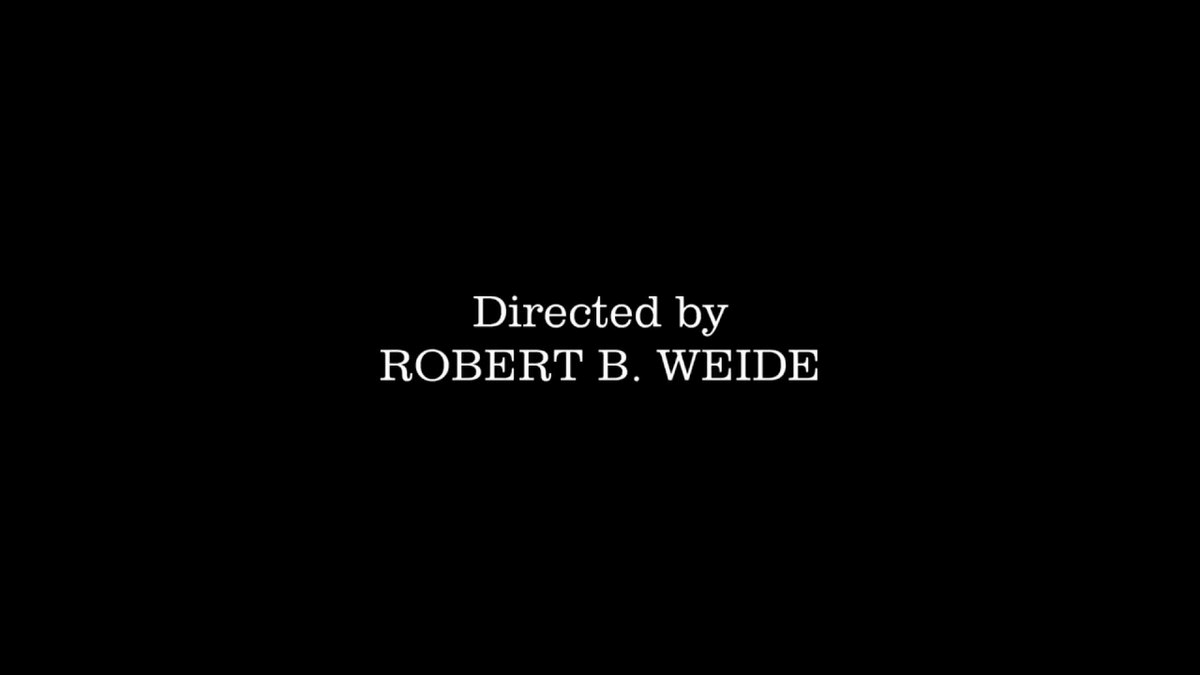

Call me maybe!! tg: @xufana / @al_potekhin

---

### Bonus: a RAG module in LangChain (LCEL)

So far we assembled the pieces of the RAG pipeline by hand: the retriever separately, generation through
`transformers.pipeline` separately. In practice these pieces are conveniently combined into one **RAG module** with the
**LangChain Expression Language (LCEL)** — a declarative way to build chains like `retriever -> prompt -> llm -> parser`
with the `|` operator.

Assembled from four parts:
1. **Retriever** — `qdrant_retriever`, `bm25_retriever`, `ensemble_retriever`.
2. **Context formatting** — a list of `Document` → one text block.
3. **Prompt template** — a template with `{context}` and `{question}`.
4. **LLM** — any LangChain-compatible wrapper. Below, `ChatOpenAI` as a stub; in a real pipeline,
   `HuggingFacePipeline(pipeline=generation_pipeline)` (the model from the QE section).

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

rag_prompt = ChatPromptTemplate.from_template(
    "Ты — ассистент, отвечающий на вопросы по контексту ниже.\n"
    "Если в контексте нет ответа, явно скажи об этом.\n\n"
    "Контекст:\n{context}\n\nВопрос: {question}\n\nОтвет:"
)

# A stub — replace with HuggingFacePipeline(pipeline=generation_pipeline)
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

rag_chain = (
    {"context": qdrant_retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt
    | llm
    | StrOutputParser()
)

question = "Как быть, если в промптах для LLM содержится нерелевантная информация?"
print(rag_chain.invoke(question))

### Bonus: the same RAG module on a local model (`HuggingFacePipeline`)

To use `generation_pipeline` instead of `ChatOpenAI`, we wrap it into `HuggingFacePipeline`. The key difference:
`transformers.pipeline` expects a **string**, not a list of messages, so we build the prompt with `PromptTemplate`, not
`ChatPromptTemplate`.

In [ ]:
from langchain_huggingface import HuggingFacePipeline
from langchain_core.prompts import PromptTemplate

local_llm = HuggingFacePipeline(pipeline=generation_pipeline)

rag_prompt_local = PromptTemplate.from_template(
    "Ты — ассистент, отвечающий на вопросы по контексту ниже.\n"
    "Если в контексте нет ответа, явно скажи об этом.\n\n"
    "Контекст:\n{context}\n\nВопрос: {question}\n\nОтвет:"
)

rag_chain_local = (
    {"context": qdrant_retriever | format_docs, "question": RunnablePassthrough()}
    | rag_prompt_local
    | local_llm
    | StrOutputParser()
)

question = "Как быть, если в промптах для LLM содержится нерелевантная информация?"
print(rag_chain_local.invoke(question))

---

## References

**RAG & retrievers:**
- [Lewis et al., 2020 — RAG for Knowledge-Intensive NLP Tasks](https://arxiv.org/abs/2005.11401)
- [Robertson & Zaragoza, 2009 — The Probabilistic Relevance Framework: BM25 and Beyond](https://dl.acm.org/doi/10.1561/1500000019)

**Advanced RAG:**
- [Gao et al., 2022 — HyDE: Precise Zero-Shot Dense Retrieval without Relevance Labels](https://arxiv.org/abs/2212.10496)
- [Yan et al., 2024 — CRAG: Corrective Retrieval Augmented Generation](https://arxiv.org/abs/2401.15884)

**LLM-as-a-judge & evaluation:**
- [Zheng et al., 2023 — Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena](https://arxiv.org/abs/2306.05685)
- [Wang et al., 2023 — Large Language Models are not Fair Evaluators](https://arxiv.org/abs/2305.17926)
- [Shankar et al., 2024 — Who Validates the Validators? Aligning LLM-Assisted Evaluation of LLM Outputs with Human Preferences](https://arxiv.org/abs/2404.12272)
- [Liu et al., 2023 — G-Eval: NLG Evaluation using GPT-4 with Better Human Alignment](https://arxiv.org/abs/2303.16634)
- [Es et al., 2023 — RAGAS: Automated Evaluation of Retrieval Augmented Generation](https://arxiv.org/abs/2309.15217)

**Embeddings:**
- [Chen et al., 2024 — BGE M3-Embedding](https://arxiv.org/abs/2402.03216)
- [MTEB Russian Leaderboard](https://huggingface.co/spaces/mteb/leaderboard?language=rus)

**Tools:**
- [LangChain LCEL](https://python.langchain.com/docs/expression_language/)
- [Qdrant Docs](https://qdrant.tech/documentation/)
- [RAGAS Framework](https://docs.ragas.io/)